In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

In [4]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)

In [5]:
kolumny = [
    'waittime'
]

data = data_raw.select(kolumny).to_pandas()


data

,waittime
0,2490
1,2489
2,2489
3,2472
4,2471
...,...
11110272,29
11110273,30
11110274,29
11110275,32


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Czas oczekiwania zapisany w sekundach
wait = pd.to_numeric(data["waittime"], errors="coerce")
wait = wait.replace([np.inf, -np.inf], np.nan).dropna()

# Kontrola jakości
print("Liczba obserwacji:", len(wait))
print("Ujemne czasy:", (wait < 0).sum())
print("Zerowe czasy:", (wait == 0).sum())

# Usuwamy ujemne czasy (do osobnego zbadania)
t = wait[wait >= 0] / 60  # minuty

# Podstawowe statystyki
statystyki = pd.Series({
    "Liczba obserwacji": len(t),
    "Średnia [min]": t.mean(),
    "Mediana [min]": t.median(),
    "Odchylenie standardowe": t.std(),
    "Wariancja": t.var(),
    "Minimum": t.min(),
    "Maksimum": t.max(),
    "Q05": t.quantile(0.05),
    "Q25": t.quantile(0.25),
    "Q75": t.quantile(0.75),
    "Q90": t.quantile(0.90),
    "Q95": t.quantile(0.95),
    "Q99": t.quantile(0.99),
    "Skośność": t.skew(),
    "Kurtoza": t.kurt(),
    "CV": t.std() / t.mean(),
    "P(T > 10 min)": (t > 10).mean(),
    "P(T > 30 min)": (t > 30).mean(),
    "P(T > 60 min)": (t > 60).mean(),
    "P(T > 120 min)": (t > 120).mean(),
    "P(T > 24 h)": (t > 1440).mean()
})

print(statystyki.round(4))


Liczba obserwacji: 11110277
Ujemne czasy: 0
Zerowe czasy: 404
Liczba obserwacji         1.111028e+07
Średnia [min]             2.386810e+01
Mediana [min]             8.016700e+00
Odchylenie standardowe    1.697390e+02
Wariancja                 2.881132e+04
Minimum                   0.000000e+00
Maksimum                  1.953842e+04
Q05                       9.333000e-01
Q25                       3.500000e+00
Q75                       1.723330e+01
Q90                       3.745000e+01
Q95                       6.913330e+01
Q99                       2.733000e+02
Skośność                  6.172460e+01
Kurtoza                   4.623129e+03
CV                        7.111500e+00
P(T > 10 min)             4.230000e-01
P(T > 30 min)             1.305000e-01
P(T > 60 min)             5.810000e-02
P(T > 120 min)            2.680000e-02
P(T > 24 h)               5.000000e-04
dtype: float64


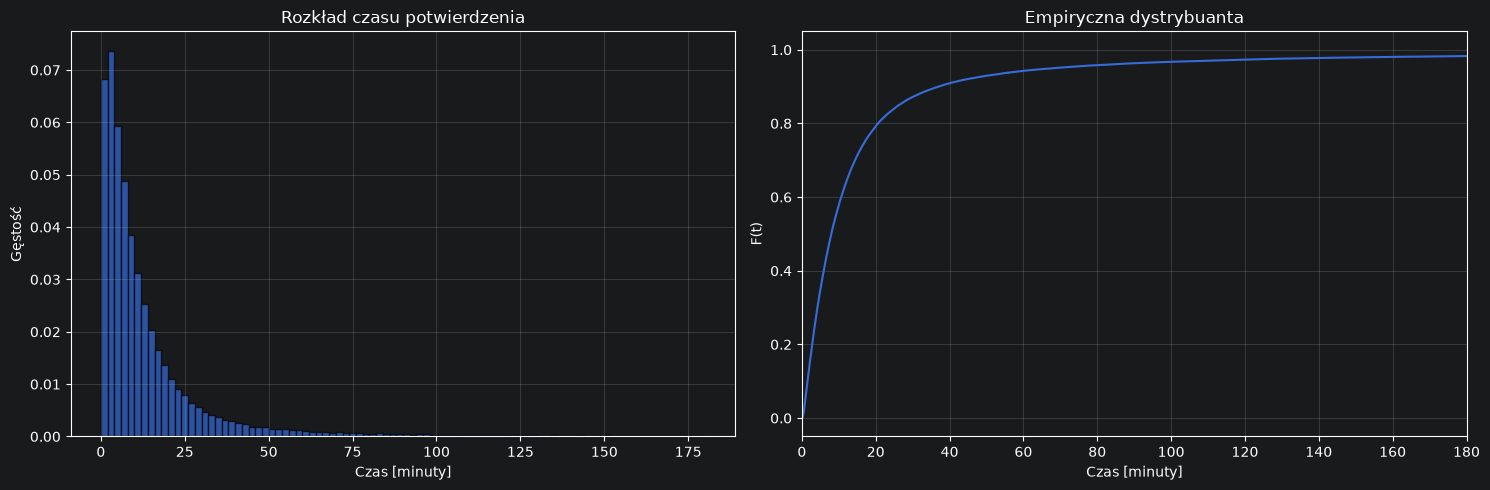

In [7]:

# Reprezentatywna próba do wykresów
proba_wykres = t.sample(
    n=min(100_000, len(t)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram w zakresie 0-180 minut
bins = np.linspace(0, 180, 91)
szerokosc = bins[1] - bins[0]

axes[0].hist(
    proba_wykres,
    bins=bins,
    weights=np.ones(len(proba_wykres)) /
            (len(proba_wykres) * szerokosc),
    edgecolor="black",
    alpha=0.7
)

axes[0].set_title("Rozkład czasu potwierdzenia")
axes[0].set_xlabel("Czas [minuty]")
axes[0].set_ylabel("Gęstość")
axes[0].grid(alpha=0.3)

# Empiryczna dystrybuanta
x = np.sort(proba_wykres.to_numpy())
F = np.arange(1, len(x) + 1) / len(x)

axes[1].plot(x, F)
axes[1].set_xlim(0, 180)
axes[1].set_title("Empiryczna dystrybuanta")
axes[1].set_xlabel("Czas [minuty]")
axes[1].set_ylabel("F(t)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:

from scipy import stats
import numpy as np
import pandas as pd

# Osobno traktujemy zerowe czasy oczekiwania
p_zero = (t == 0).mean()
dodatnie = t[t > 0]

# Próba do estymacji numerycznej
proba = dodatnie.sample(
    n=min(100_000, len(dodatnie)),
    random_state=42
).to_numpy()

# Rozkłady i liczba estymowanych parametrów
rozklady = {
    "Wykladniczy": (stats.expon, 1),
    "Gamma": (stats.gamma, 2),
    "Weibull": (stats.weibull_min, 2),
    "Lognormalny": (stats.lognorm, 2),
    "Log-logistyczny": (stats.fisk, 2)
}

wyniki = []
dopasowania = {}

for nazwa, (rozklad, k) in rozklady.items():

    # Estymacja największej wiarygodności
    params = rozklad.fit(proba, floc=0)

    # Logarytm funkcji wiarygodności
    logL = np.sum(rozklad.logpdf(proba, *params))

    # Kryteria informacyjne
    aic = 2 * k - 2 * logL
    bic = k * np.log(len(proba)) - 2 * logL

    wyniki.append({
        "Rozkład": nazwa,
        "AIC": aic,
        "BIC": bic,
        "Log-likelihood": logL
    })

    dopasowania[nazwa] = params

wyniki = (
    pd.DataFrame(wyniki)
    .sort_values("AIC")
    .reset_index(drop=True)
)

display(wyniki.round(2))

najlepszy = wyniki.iloc[0]["Rozkład"]

print("Najlepszy według AIC:", najlepszy)
print("Parametry:", dopasowania[najlepszy])
print("Udział zerowych czasów:", p_zero)


,Rozkład,AIC,BIC,Log-likelihood
0,Log-logistyczny,749968.93,749987.96,-374982.47
1,Lognormalny,752050.34,752069.36,-376023.17
2,Weibull,782136.63,782155.66,-391066.32
3,Gamma,807183.36,807202.39,-403589.68
4,Wykladniczy,834288.17,834297.69,-417143.09


Najlepszy według AIC: Log-logistyczny
Parametry: (np.float64(1.3805500336156027), 0, np.float64(7.861042881262865))
Udział zerowych czasów: 3.636272975012234e-05


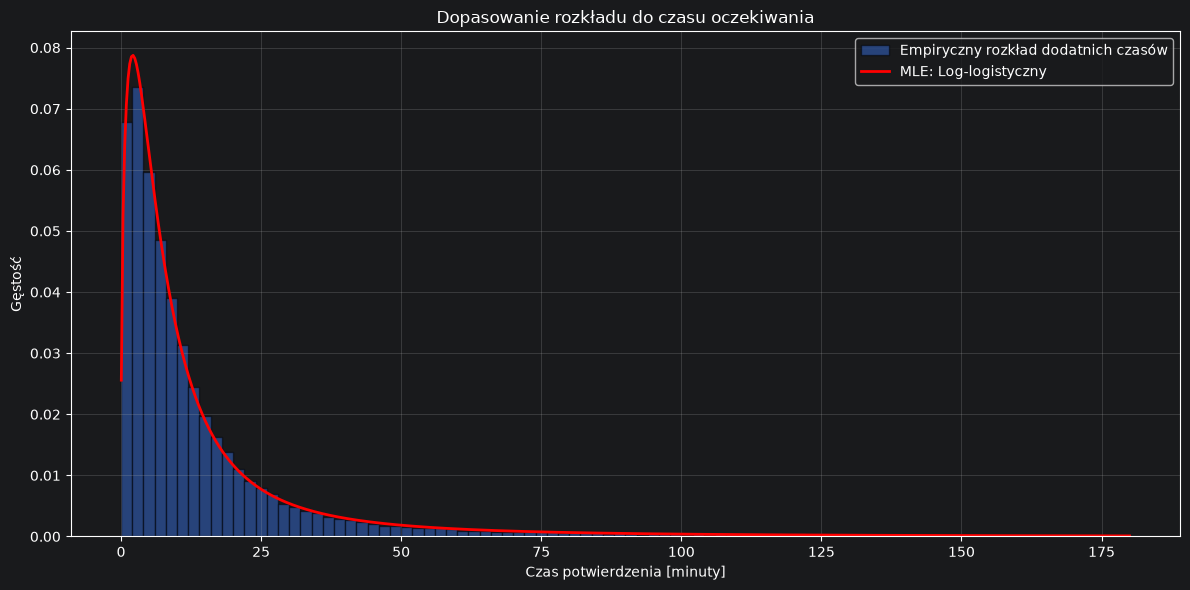

In [11]:
rozklad, _ = rozklady[najlepszy]
params = dopasowania[najlepszy]

x = np.linspace(0.05, 180, 600)

plt.figure(figsize=(12, 6))

bins = np.linspace(0, 180, 91)
width = bins[1] - bins[0]

plt.hist(
    proba,
    bins=bins,
    weights=np.ones(len(proba)) / (len(proba) * width),
    alpha=0.5,
    edgecolor="black",
    label="Empiryczny rozkład dodatnich czasów"
)

plt.plot(
    x,
    rozklad.pdf(x, *params),
    color="red",
    linewidth=2,
    label=f"MLE: {najlepszy}"
)

plt.xlabel("Czas potwierdzenia [minuty]")
plt.ylabel("Gęstość")
plt.title("Dopasowanie rozkładu do czasu oczekiwania")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
czasy_testowe = [10, 20, 30, 60, 120, 1440]

porownanie = pd.DataFrame({
    "Czas [min]": czasy_testowe,
    "Empiryczne P(T>t)": [
        (t > x).mean() for x in czasy_testowe
    ],
    "Modelowe P(T>t)": [
        (1 - p_zero) * rozklad.sf(x, *params)
        for x in czasy_testowe
    ]
})

display(porownanie.round(4))

,Czas [min],Empiryczne P(T>t),Modelowe P(T>t)
0,10,0.4230,0.4177
1,20,0.2113,0.2160
2,30,0.1305,0.1360
3,60,0.0581,0.0570
4,120,0.0268,0.0227
5,1440,0.0005,0.0008


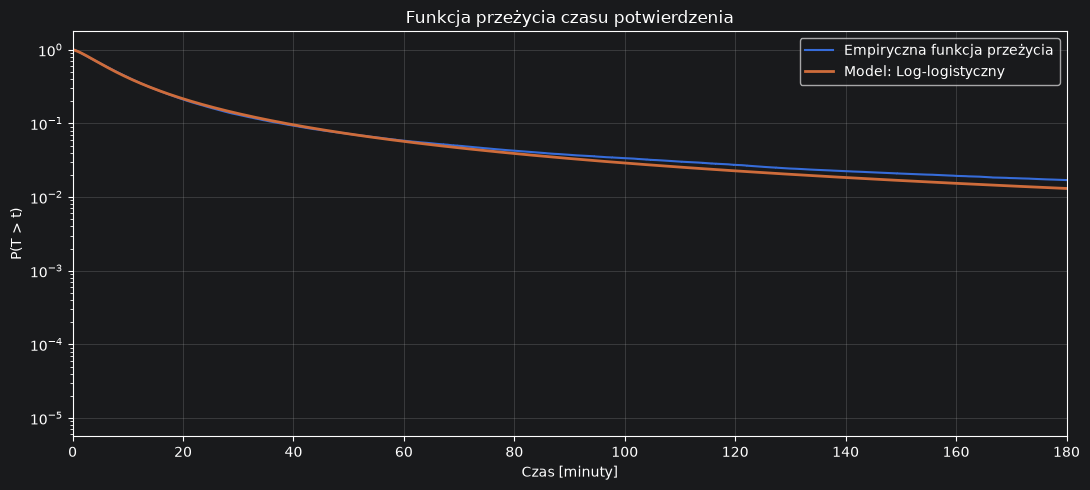

In [13]:
x_sorted = np.sort(proba)
S = 1 - np.arange(1, len(proba) + 1) / len(proba)

plt.figure(figsize=(11, 5))

plt.semilogy(
    x_sorted[:-1],
    S[:-1],
    label="Empiryczna funkcja przeżycia"
)

plt.semilogy(
    x,
    rozklad.sf(x, *params),
    label=f"Model: {najlepszy}",
    linewidth=2
)

plt.xlim(0, 180)
plt.xlabel("Czas [minuty]")
plt.ylabel("P(T > t)")
plt.title("Funkcja przeżycia czasu potwierdzenia")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()